## Pegasus Evaluation: Fine-Tuning

Section C.1. Setup, methods and metrics: `2a_base_case.ipynb`; parameters: `pegasus/evaluation_setup.py`. C.2:
`2f_optimization.ipynb`.

In [1]:
# Data source of C.1: "real", the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py);
# C.1 reads the bound of Pegasus from B.1 on all chains (2a_base_case.ipynb), which exists for the real data only
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
import pandas as pd
from pegasus.figures import math_label, sweep_table
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))
print(f"{data_source} data, {len(seeds)} seeds")

real data, 3 seeds


### C.1 Fine-Tuning Bounds with End-to-End Samples

One chain of B.1, `C1_CHAIN`. Its held-out runs (up to `MAX_WORKERS` workers per service, as in B.1 on all chains in
`2a_base_case.ipynb`) are split at random into up to `c1_sizes[-1]` end-to-end samples and a fixed test set. With the
first $n$ samples (one value of `c1_sizes` per setting; $n = 0$ is the bound of B.1 without fine-tuning), the bound of
Pegasus is multiplied by one split-conformal factor, the $\lceil (n+1)\gamma \rceil$-th smallest ratio measured
quantile ÷ bound over the samples, with $\gamma$ = `confidence` (`pegasus/finetuning.py`). That rank exists only if it
is at most $n$, i.e. for $n \ge \gamma / (1 - \gamma)$ (`c1_calibrated`); with fewer samples Pegasus keeps the
bound of B.1, while the two baselines, which train on the samples, already change.

- **Chain:** chosen once from an earlier evaluation of C.1 on every chain of B.1: a chain on which Pegasus held at
  every fine-tuned $n$ under every seed, whose bound without samples was among the tighter ones, and whose tightness
  fell clearly from $n = 0$ to $n$ = `c1_sizes[-1]`. It is fixed here and not selected anew.
- **Pegasus (ours):** the bound of B.1 with its load-aware models, the default of B.1 (`2a_base_case.ipynb`,
  `load_aware_b4.py`), read from the cached results of B.1 on all chains and never recomputed here (if that cache is
  missing, run `2a_base_case.ipynb` first).
- **Baselines trained on the samples:** *Quantile Sum* (GP of the latency quantile per service inside the chain, summed)
  and *Fluxion-style* (one GP per position, fed by the position before it, `pegasus/baselines_chain.py`). Both predict
  the quantile; neither is a bound.

Figure: `figures/tsc/experimental-results/c1_finetuning_<data source>`: the tightness (latency ÷ measured quantile per test run, the median
over the test runs) over the number of end-to-end samples $n$; the line is the median over the seeds and the band the
range over the seeds; a filled marker means that the method holds under every seed.

In [2]:
if "C.1" in skipped or data_source != "real":
    print("C.1 skipped: real data only (the bound of Pegasus comes from B.1 on all chains)")
else:
    # C.1 on one chain: the bound of B.1 with end-to-end samples. This cell imports what it needs itself.
    import joblib
    from pegasus.finetuning import COLORS as C1_COLORS, FLUXION, QUANTILE_SUM, finetuned_bound, fluxion_style, quantile_sum, split_samples
    from load_aware_b4 import VARIANT   # the load-aware models of Pegasus in B.1 (load_aware_b4.py next to this notebook)

    # the chain of C.1, chosen once from an earlier evaluation of C.1 on every chain (markdown above)
    C1_CHAIN = f"b1-vision-1-single+b1u-max{MAX_WORKERS}"
    METHOD_COLORS.update(C1_COLORS)   # colors of the two baselines
    # the smallest number of samples at which the conformal rank ceil((n + 1) * confidence) is at most n; below it Pegasus
    # keeps the bound of B.1 (calibration_factor), while the two baselines already train on the samples
    c1_calibrated = int(np.ceil(confidence / (1 - confidence) - 1e-9))
    # number of end-to-end samples; 0 is the bound of B.1 on the test set without fine-tuning; up to 50 of the held-out runs of
    # the chain, which leaves the rest as the test set
    c1_sizes = [0, 5, 10, 20, 30, 40, 50]

    # B.1 on all chains of 2a_base_case.ipynb: the newest file of its cache (under the default chain option), read only
    b1_all_path = max(CACHE.glob(f"b1_all_chains_real+{DEFAULT_CHAINS}_*.joblib"), key=lambda path: path.stat().st_mtime)
    b1_all = joblib.load(b1_all_path)
    assert C1_CHAIN in b1_all["unseen_chains"] and VARIANT in b1_all["unseen"][(C1_CHAIN, seeds[0])].latencies, (
        f"{b1_all_path.name} has no load-aware bound of {C1_CHAIN}: run 2a_base_case.ipynb first")

    def compute():
        results, truth = {}, {}   # (size, seed) -> name -> (group, latency per test run) / (measured quantile, its lower edge)
        with warnings.catch_warnings():
            # the GPs of the two baselines are fitted on few samples, and scikit-learn warns where their hyperparameters end at their bounds
            warnings.simplefilter("ignore", ConvergenceWarning)
            # the held-out runs of the chain with the latencies of every service and the inputs, which the two baselines train on;
            # the training data of a seed does not enter them, so the data of one seed serves every seed
            data = load_chain_data("real", experiment=C1_CHAIN, level=1 - alpha, coverage_check=coverage_check, seed=[seed, seeds[0]],
                                   n_train=base_options["n_train"], training_campaign=BENCHMARKS_V2)
            for s in seeds:
                b1 = b1_all["unseen"][(C1_CHAIN, s)]
                assert np.array_equal(b1.measured, data.measured, equal_nan=True), f"{C1_CHAIN}: other held-out runs than in B.1"
                samples, test = split_samples(len(b1.measured), c1_sizes[-1], np.random.default_rng([seed, s, 100]))
                for size in c1_sizes:
                    # Pegasus: the bound of B.1 with its load-aware models, fine-tuned with the first `size` samples (finetuned_bound)
                    methods = {PROPOSED: ("proposed", finetuned_bound(b1.latencies[VARIANT], b1.measured, samples[:size], test,
                                                                      miscoverage=1 - confidence))}
                    if size > 0:
                        methods[QUANTILE_SUM] = ("baseline", quantile_sum(data, samples[:size], test, alpha))
                        methods[FLUXION] = ("baseline", fluxion_style(data, samples[:size], test, alpha))
                    results[(size, s)] = methods
                    truth[(size, s)] = (b1.measured[test], b1.measured_low[test])
        return dict(c1_results=results, c1_truth=truth)

    # the chain and the file of B.1 on all chains enter the key: new results of 2a compute these anew
    globals().update(cached("c1_finetuning_chain", data_source, compute,
                            inputs=dict(c1_sizes=c1_sizes, chain=C1_CHAIN, b1_all_chains=b1_all_path.name)))
    c1_statistics = sweep_statistics(c1_results, c1_truth, c1_sizes, seeds, confidence)   # name -> coverage, tightness, holds, computed
    c1_test = len(c1_truth[(c1_sizes[0], seeds[0])][0])
    print(f"chain {C1_CHAIN.split('+')[0].removeprefix('b1-').removesuffix('-single')} ({' → '.join(b1_all['unseen'][(C1_CHAIN, seeds[0])].path)}), "
          f"{c1_test} test runs per seed, {len(seeds)} seeds; B.1 on all chains from {b1_all_path.name}")

c1_finetuning_chain: results computed and saved to cache\evaluation\c1_finetuning_chain_real+b1+b1u-max4_72bd7709b44ef974.joblib
chain vision-1 (detector → transformer → compressor), 99 test runs per seed, 3 seeds; B.1 on all chains from b1_all_chains_real+b1+b1u-max4_def3ab0ebafba1ad.joblib


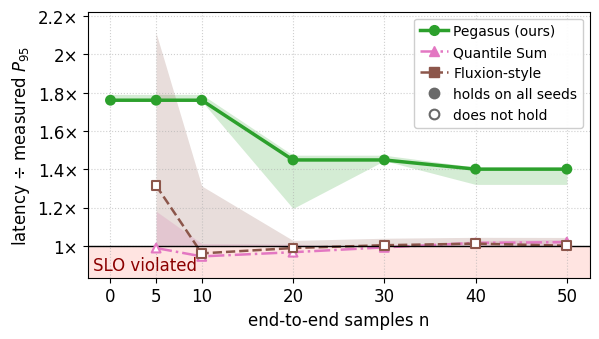

tightness (median over the seeds; ● holds, ○ does not):


,n = 0,n = 5,n = 10,n = 20,n = 30,n = 40,n = 50
Pegasus (ours),1.76× ●,1.76× ●,1.76× ●,1.45× ●,1.45× ●,1.40× ●,1.40× ●
Quantile Sum,–,0.99× ○,0.94× ○,0.97× ○,0.99× ○,1.02× ○,1.02× ○
Fluxion-style,–,1.31× ○,0.96× ○,0.99× ○,1.00× ○,1.01× ○,1.00× ○


In [3]:
if "C.1" in skipped or data_source != "real":
    print("C.1 skipped: real data only")
else:
    from pegasus.finetuning import finetuning_figure
    # source: c1_statistics of the cell above
    finetuning_figure(c1_sizes, c1_statistics, p_label, output=Path("../../figures/tsc") / f"c1_finetuning_{data_source}",
                      # one column at the upper right, clear of the drop of the line between the first sample sizes
                      legend_options=dict(ncol=1, locations=("upper right",)))
    print("tightness (median over the seeds; ● holds, ○ does not):")
    display(sweep_table(c1_sizes, c1_statistics, list(c1_statistics), lambda size: f"n = {size}"))